# MSCS 634 – Lab 2: KNN and Radius Neighbors Classification

**Student Name:** Sandeep Reddy Polareddy  
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**Assignment:** Lab 2 – K-Nearest Neighbors and Radius Neighbors Classification

## Introduction

The purpose of this lab is to explore and compare the performance of K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) classification algorithms using the Wine Dataset from the Scikit-learn library.

The Wine Dataset contains 178 wine samples, three target classes, and 13 chemical features. This experiment evaluates how different parameter values influence classification accuracy. The lab includes dataset exploration, an 80/20 train-test split, model implementation, accuracy evaluation, visualizations, and a comparison of the two algorithms.


## 1. Import Required Libraries

The following libraries are used to load and explore the dataset, train the classifiers, calculate accuracy, and create visualizations.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Load the Wine Dataset

Load the Wine Dataset from Scikit-learn and place its 13 features and target class into a Pandas DataFrame.


In [3]:
wine = load_wine()

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nFeature names:")
print(wine.feature_names)

print("\nTarget class names:")
print(wine.target_names)


First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Dataset shape: (178, 14)

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target class names:
['class_0' 'class_1' 'class_2']


## 3. Explore the Dataset

Review the data types, descriptive statistics, missing values, and distribution of the three wine classes.


In [4]:
print("Dataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

print("\nMissing values by column:")
display(df.isnull().sum())

print("\nClass distribution:")
display(df["target"].value_counts().sort_index())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null 

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000



Missing values by column:


alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


Class distribution:


target
0    59
1    71
2    48
Name: count, dtype: int64

### Visualize the Class Distribution


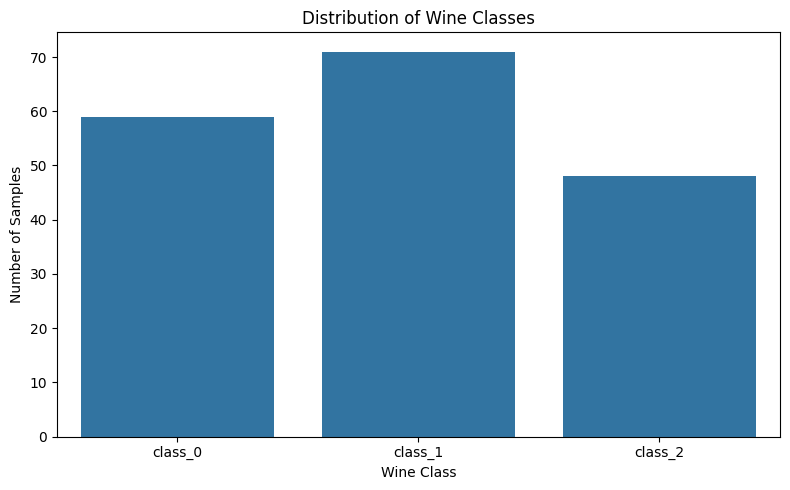

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="target")
plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.xticks(ticks=[0, 1, 2], labels=wine.target_names)
plt.tight_layout()
plt.show()


## 4. Split the Dataset

Separate the features from the target and split the data into 80% training and 20% testing sets. Stratification preserves the approximate class proportions in both sets. The fixed random state makes the split reproducible.


In [6]:
X = wine.data
y = wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Training samples: 142
Testing samples: 36
Training feature shape: (142, 13)
Testing feature shape: (36, 13)


## 5. Implement K-Nearest Neighbors (KNN)

Train and evaluate KNN classifiers using the required values of *k*: 1, 5, 11, 15, and 21. Accuracy is calculated on the held-out test set for each model.


In [7]:
k_values = [1, 5, 11, 15, 21]
knn_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    knn_accuracies.append(accuracy)

    print(f"K = {k:2d} | Accuracy = {accuracy:.4f} ({accuracy:.2%})")

knn_results = pd.DataFrame({
    "K Value": k_values,
    "Accuracy": knn_accuracies
})

print("\nKNN accuracy results:")
display(knn_results)


K =  1 | Accuracy = 0.7778 (77.78%)
K =  5 | Accuracy = 0.8056 (80.56%)
K = 11 | Accuracy = 0.8056 (80.56%)
K = 15 | Accuracy = 0.8056 (80.56%)
K = 21 | Accuracy = 0.8056 (80.56%)

KNN accuracy results:


,K Value,Accuracy
0,1,0.777778
1,5,0.805556
2,11,0.805556
3,15,0.805556
4,21,0.805556


### Visualize KNN Accuracy


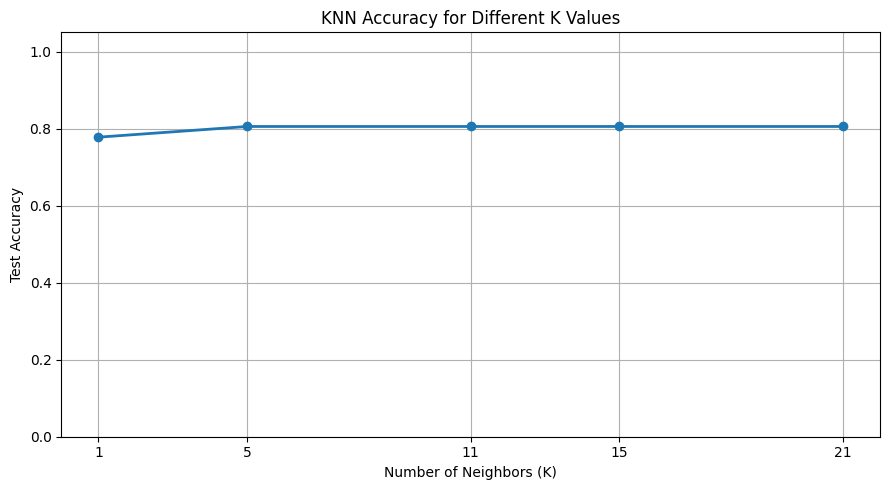

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(k_values, knn_accuracies, marker="o", linewidth=2)
plt.title("KNN Accuracy for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Accuracy")
plt.xticks(k_values)
plt.ylim(0, 1.05)
plt.grid(True)
plt.tight_layout()
plt.show()


## 6. Implement Radius Neighbors (RNN)

Evaluate Radius Neighbors using the required radius values: 350, 400, 450, 500, 550, and 600.

**Preprocessing decision:** The specified radius values are large and are intended to be evaluated on the original feature scale, so this experiment does not standardize the features. This means features with larger numerical ranges can have more influence on Euclidean distance. The `outlier_label="most_frequent"` setting assigns the most frequent training class when a test observation has no training samples within its radius.


In [9]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_accuracies = []

for radius in radius_values:
    rnn = RadiusNeighborsClassifier(
        radius=radius,
        outlier_label="most_frequent"
    )
    rnn.fit(X_train, y_train)

    y_pred = rnn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    rnn_accuracies.append(accuracy)

    print(f"Radius = {radius:3d} | Accuracy = {accuracy:.4f} ({accuracy:.2%})")

rnn_results = pd.DataFrame({
    "Radius": radius_values,
    "Accuracy": rnn_accuracies
})

print("\nRadius Neighbors accuracy results:")
display(rnn_results)


Radius = 350 | Accuracy = 0.7222 (72.22%)
Radius = 400 | Accuracy = 0.6944 (69.44%)
Radius = 450 | Accuracy = 0.6944 (69.44%)
Radius = 500 | Accuracy = 0.6944 (69.44%)
Radius = 550 | Accuracy = 0.6667 (66.67%)
Radius = 600 | Accuracy = 0.6667 (66.67%)

Radius Neighbors accuracy results:


,Radius,Accuracy
0,350,0.722222
1,400,0.694444
2,450,0.694444
3,500,0.694444
4,550,0.666667
5,600,0.666667


### Visualize Radius Neighbors Accuracy


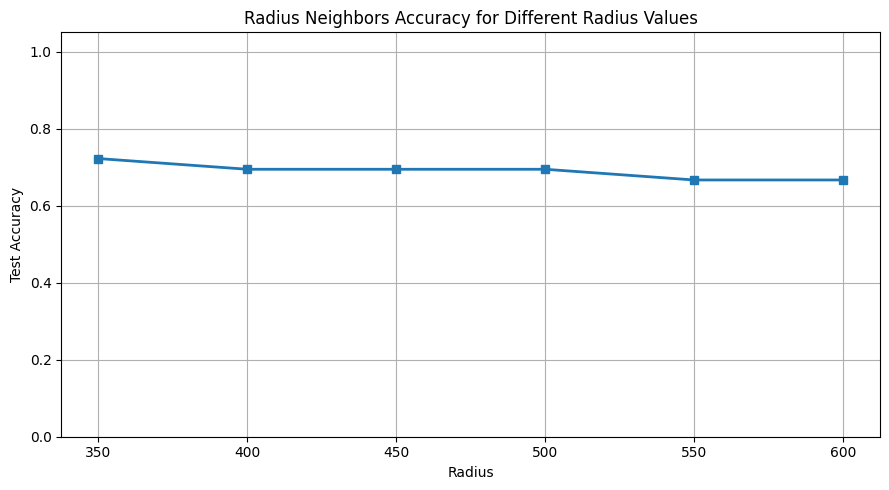

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(radius_values, rnn_accuracies, marker="s", linewidth=2)
plt.title("Radius Neighbors Accuracy for Different Radius Values")
plt.xlabel("Radius")
plt.ylabel("Test Accuracy")
plt.xticks(radius_values)
plt.ylim(0, 1.05)
plt.grid(True)
plt.tight_layout()
plt.show()


## 7. Compare the Best KNN and RNN Configurations

Identify the parameter value that produced the highest test accuracy for each algorithm and compare the two best results.


In [11]:
best_knn_index = int(np.argmax(knn_accuracies))
best_knn_k = k_values[best_knn_index]
best_knn_accuracy = knn_accuracies[best_knn_index]

best_rnn_index = int(np.argmax(rnn_accuracies))
best_rnn_radius = radius_values[best_rnn_index]
best_rnn_accuracy = rnn_accuracies[best_rnn_index]

print("Best KNN configuration")
print(f"K = {best_knn_k}")
print(f"Accuracy = {best_knn_accuracy:.4f} ({best_knn_accuracy:.2%})")

print("\nBest Radius Neighbors configuration")
print(f"Radius = {best_rnn_radius}")
print(f"Accuracy = {best_rnn_accuracy:.4f} ({best_rnn_accuracy:.2%})")

if best_knn_accuracy > best_rnn_accuracy:
    print("\nKNN achieved the higher test accuracy.")
elif best_rnn_accuracy > best_knn_accuracy:
    print("\nRadius Neighbors achieved the higher test accuracy.")
else:
    print("\nBoth algorithms achieved the same highest test accuracy.")


Best KNN configuration
K = 5
Accuracy = 0.8056 (80.56%)

Best Radius Neighbors configuration
Radius = 350
Accuracy = 0.7222 (72.22%)

KNN achieved the higher test accuracy.


### Compare the Best Accuracy of Each Algorithm

This chart compares the best test accuracy achieved by each algorithm. The K and radius values are different types of parameters, so their raw values should not be plotted on a shared parameter axis.


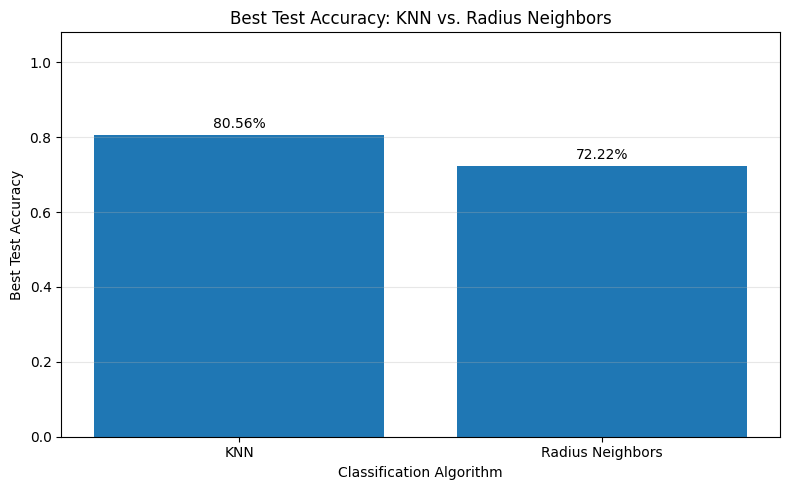

In [12]:
model_names = ["KNN", "Radius Neighbors"]
best_accuracies = [best_knn_accuracy, best_rnn_accuracy]

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, best_accuracies)
plt.title("Best Test Accuracy: KNN vs. Radius Neighbors")
plt.xlabel("Classification Algorithm")
plt.ylabel("Best Test Accuracy")
plt.ylim(0, 1.08)
plt.grid(axis="y", alpha=0.3)

for bar, accuracy in zip(bars, best_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.02,
        f"{accuracy:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()


## 8. Classification Report and Confusion Matrix for the Best KNN Model

The classification report provides precision, recall, and F1-score for each wine class. The confusion matrix shows the number of correct and incorrect predictions for each class.


Classification report for the best KNN model:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.77      0.71      0.74        14
     class_2       0.64      0.70      0.67        10

    accuracy                           0.81        36
   macro avg       0.80      0.80      0.80        36
weighted avg       0.81      0.81      0.81        36



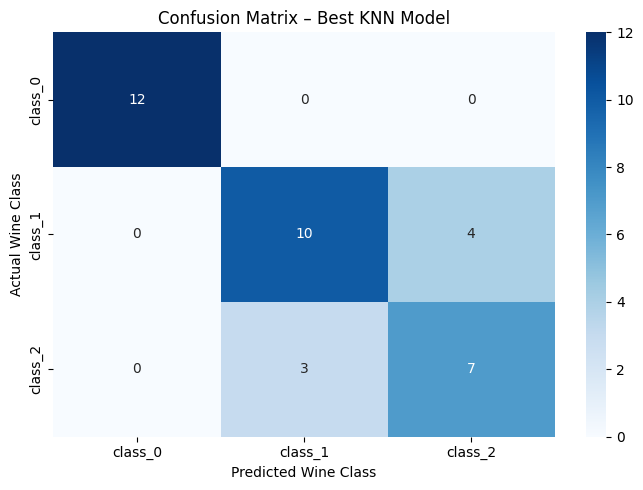

In [13]:
best_knn_model = KNeighborsClassifier(n_neighbors=best_knn_k)
best_knn_model.fit(X_train, y_train)

best_knn_predictions = best_knn_model.predict(X_test)

print("Classification report for the best KNN model:")
print(classification_report(
    y_test,
    best_knn_predictions,
    target_names=wine.target_names
))

cm = confusion_matrix(y_test, best_knn_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)
plt.title("Confusion Matrix – Best KNN Model")
plt.xlabel("Predicted Wine Class")
plt.ylabel("Actual Wine Class")
plt.tight_layout()
plt.show()


## 9. Final Results Tables

The following tables bring together all tested parameter values and their corresponding test accuracies.


In [14]:
print("KNN results:")
display(knn_results)

print("Radius Neighbors results:")
display(rnn_results)

summary = pd.DataFrame({
    "Algorithm": ["KNN", "Radius Neighbors"],
    "Best Parameter": [best_knn_k, best_rnn_radius],
    "Best Test Accuracy": [best_knn_accuracy, best_rnn_accuracy]
})

print("Best model summary:")
display(summary)


KNN results:


,K Value,Accuracy
0,1,0.777778
1,5,0.805556
2,11,0.805556
3,15,0.805556
4,21,0.805556


Radius Neighbors results:


,Radius,Accuracy
0,350,0.722222
1,400,0.694444
2,450,0.694444
3,500,0.694444
4,550,0.666667
5,600,0.666667


Best model summary:


,Algorithm,Best Parameter,Best Test Accuracy
0,KNN,5,0.805556
1,Radius Neighbors,350,0.722222


## 10. Results, Observations, and Discussion

### KNN Observations

KNN was evaluated using *k* values of 1, 5, 11, 15, and 21. KNN assigns a class based on the labels of a fixed number of nearest training observations. A small value of *k* can make predictions sensitive to individual observations, while a larger value considers a broader neighborhood. The accuracy results and line graph show how the choice of *k* affected test performance.

### Radius Neighbors Observations

Radius Neighbors was evaluated using radius values of 350, 400, 450, 500, 550, and 600. Unlike KNN, this method considers all training observations within a specified distance. Increasing the radius can include more observations in a prediction. If no observations fall within the radius, the configured `outlier_label` assigns the most frequent training class.

### Comparison of the Algorithms

KNN uses a fixed number of nearest neighbors, whereas Radius Neighbors uses a fixed distance threshold. KNN can be preferable when a consistent number of neighbors is desired. Radius Neighbors can be useful when a meaningful distance threshold is available and the number of nearby observations should vary with local data density.

The best-performing configuration for each algorithm is identified by comparing its test accuracy. The algorithm with the higher best test accuracy performed better in this particular experiment. This conclusion applies to the selected train-test split and parameter values; it does not establish that one algorithm is always superior.

### Challenges and Decisions

One important consideration was the difference in numerical scales among the Wine Dataset features. Because the assignment specifies radius values from 350 to 600, the Radius Neighbors experiment retained the original feature values. Consequently, features with larger numerical ranges can have a stronger influence on Euclidean distance. The outlier-label option was used to handle test samples without neighbors inside the selected radius.

The experiment also illustrates why model parameters should be selected based on measured performance rather than assumed to work equally well across datasets.

### Conclusion

This lab provided practical experience implementing and evaluating KNN and Radius Neighbors classifiers with Python and Scikit-learn. The results demonstrate that parameter selection affects classification accuracy and that the two algorithms define neighborhoods differently. The accuracy tables, visualizations, and classification report provide evidence for comparing their performance on the Wine Dataset.


## 11. Reproducibility Notes

- Dataset: Scikit-learn Wine Dataset.
- Samples: 178.
- Features: 13 chemical measurements.
- Target classes: 3 wine classes.
- Train-test split: 80% training and 20% testing.
- Stratification: enabled.
- Random state: 42.
- KNN values: 1, 5, 11, 15, and 21.
- Radius values: 350, 400, 450, 500, 550, and 600.
- Metric: classification accuracy on the held-out test set.

